## <span style="color:#1F4E79;">**Full CDM Probability Model**</span>

This notebook implements and tests the full Context-Dependent Model using
PyTorch. We begin with a small synthetic experiment and later increase the
number of items to study when the full model becomes computationally expensive.

In [4]:
# Import libraries and reusable CDM functions.
from math import comb
import matplotlib.pyplot as plt
import pandas as pd
import torch
import numpy as np
from pathlib import Path
from time import perf_counter
from context_dependent_model import *

In [5]:
PROJECT_ROOT = next(
    directory
    for directory in (
        Path.cwd(),
        *Path.cwd().parents,
    )
    if (directory / "pyproject.toml").exists()
)

CDM_CDM_FIGURE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "images"
    / "experiments"
    / "context_dependent_model"
    / "cdm_cdm"
)

CDM_CDM_FIGURE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

CDM_CDM_FIGURE_DIRECTORY

PosixPath('/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/context_dependent_model/cdm_cdm')

In [6]:
# Define settings shared by the CDM experiments.

SEED = 20260831

NUMBER_OF_ITEMS = 5
NUMBER_OF_OBSERVATIONS = 1_000
CHOICE_SET_SIZES = (2, 3)
PARAMETER_SCALE = 0.4

DEVICE = torch.device("cpu")
DTYPE = torch.float64
TRAIN_FRACTION = 0.8
torch.manual_seed(SEED)
LEARNING_RATE = 0.05
GRADIENT_TOLERANCE = 1e-5
NLL_TOLERANCE = 1e-9
CONVERGENCE_PATIENCE = 50
MAXIMUM_EPOCHS = 5_000

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

experiment_settings = pd.DataFrame({
    "Setting": [
        "Random seed",
        "Number of items",
        "Number of observations",
        "Choice-set sizes",
        "Parameter scale",
        "PyTorch device",
        "PyTorch dtype",
        "Training fraction",
        "Learning rate",
        "Gradient tolerance",
        "NLL tolerance",
        "Convergence patience",
        "Maximum epochs",
    ],
    "Value": [
        SEED,
        NUMBER_OF_ITEMS,
        NUMBER_OF_OBSERVATIONS,
        str(CHOICE_SET_SIZES),
        PARAMETER_SCALE,
        str(DEVICE),
        str(DTYPE),
        TRAIN_FRACTION,
        LEARNING_RATE,
        GRADIENT_TOLERANCE,
        NLL_TOLERANCE,
        CONVERGENCE_PATIENCE,
        MAXIMUM_EPOCHS,
    ],
})

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,5
2,Number of observations,1000
3,Choice-set sizes,"(2, 3)"
4,Parameter scale,0.4
5,PyTorch device,cpu
6,PyTorch dtype,torch.float64
7,Training fraction,0.8
8,Learning rate,0.05
9,Gradient tolerance,0.0


## Reusable CDM Functions

| Function or class | Purpose |
|---|---|
| `center_cdm_parameters()` | Sets the diagonal to zero and centres the interaction parameters. |
| `cdm_choice_utilities()` | Calculates the utility of each available item. |
| `cdm_choice_probabilities()` | Converts the CDM utilities into choice probabilities. |
| `average_cdm_negative_log_likelihood()` | Evaluates how well the model explains the observed choices. |
| `FullContextDependentModel` | Stores the trainable full CDM interaction matrix. |
| `generate_cdm_parameters()` | Generates a synthetic CDM interaction matrix. |
| `generate_uniform_choice_sets()` | Samples choice sets containing two or three items. |
| `generate_cdm_choice_data()` | Generates the selected item for every choice observation. |
| `CDMChoiceData` | Stores the choice sets, masks and observed choices together. |
| `split_cdm_choice_data()` | Divides the observations into reproducible training and test datasets. |
| `optimize_full_cdm_with_adam()` | Estimates the full CDM interaction matrix using PyTorch Adam. |
| `CDMOptimizationResult` | Stores the estimated parameters and convergence information. |
| `cdm_parameter_recovery_error()` | Calculates RMSE between the true and estimated context effects. |
| `run_cdm_observation_scaling_experiment()` | Repeats CDM recovery while increasing the number of observations. |

### <span style="color:#1F4E79;">Experiment 1: Generate Synthetic CDM Choices</span>



We begin with five items and 1,000 choice observations. Each observation
contains either two or three items. The choices are generated from a known
interaction matrix so that parameter recovery can be checked later.

In [7]:
# Generate the true interaction matrix and synthetic CDM choices.

true_interactions = generate_cdm_parameters(
    number_of_items=NUMBER_OF_ITEMS,
    parameter_scale=PARAMETER_SCALE,
    random_seed=SEED,
    device=DEVICE,
    dtype=DTYPE,
)

cdm_data = generate_cdm_choice_data(
    interaction_matrix=true_interactions,
    number_of_observations=NUMBER_OF_OBSERVATIONS,
    choice_set_sizes=CHOICE_SET_SIZES,
    random_seed=SEED,
)

In [8]:
# Summarise the generated interaction matrix and choice observations.

observed_set_sizes = cdm_data.choice_mask.sum(dim=1)

generation_summary = pd.DataFrame({
    "Quantity": [
        "Interaction-matrix shape",
        "Number of observations",
        "Two-item observations",
        "Three-item observations",
        "Smallest chosen-item index",
        "Largest chosen-item index",
        "Sum of interaction parameters",
    ],
    "Value": [
        str(tuple(true_interactions.shape)),
        NUMBER_OF_OBSERVATIONS,
        int((observed_set_sizes == 2).sum()),
        int((observed_set_sizes == 3).sum()),
        int(cdm_data.chosen_items.min()),
        int(cdm_data.chosen_items.max()),
        f"{true_interactions.sum().item():.4e}",
    ],
})

generation_summary

,Quantity,Value
0,Interaction-matrix shape,"(5, 5)"
1,Number of observations,1000
2,Two-item observations,485
3,Three-item observations,515
4,Smallest chosen-item index,0
5,Largest chosen-item index,4
6,Sum of interaction parameters,-2.2204e-16


### Item Appearance and Choice Summary

Before estimating the model, we check whether every item appears sufficiently
often in the generated data. The observed choice rate is the number of times an
item was chosen divided by the number of times it appeared.

In [9]:
# Check how often each item appeared and was chosen.

valid_items = cdm_data.choice_sets[
    cdm_data.choice_mask
].cpu()

chosen_items = cdm_data.chosen_items.cpu()

appearance_counts = torch.bincount(
    valid_items,
    minlength=NUMBER_OF_ITEMS,
)

choice_counts = torch.bincount(
    chosen_items,
    minlength=NUMBER_OF_ITEMS,
)

observed_choice_rates = (
    choice_counts / appearance_counts
)

item_summary = pd.DataFrame({
    "Item": range(NUMBER_OF_ITEMS),
    "Appearances": appearance_counts.numpy(),
    "Times chosen": choice_counts.numpy(),
    "Observed choice rate": observed_choice_rates.numpy(),
})

item_summary.style.format({
    "Appearances": "{:,}",
    "Times chosen": "{:,}",
    "Observed choice rate": "{:.4f}",
})

,Item,Appearances,Times chosen,Observed choice rate
0,0,510,134,0.2627
1,1,497,237,0.4769
2,2,506,221,0.4368
3,3,493,155,0.3144
4,4,509,253,0.4971


In [10]:
# Display the true interaction matrix used to generate the data.

item_labels = [
    f"Item {item_index}"
    for item_index in range(NUMBER_OF_ITEMS)
]

true_parameter_table = pd.DataFrame(
    true_interactions.detach().cpu().numpy(),
    index=[
        f"Target {item_index}"
        for item_index in range(NUMBER_OF_ITEMS)
    ],
    columns=[
        f"Context {item_index}"
        for item_index in range(NUMBER_OF_ITEMS)
    ],
)

true_parameter_table.style.format("{:.4f}").background_gradient(
    cmap="coolwarm",
    axis=None,
)


,Context 0,Context 1,Context 2,Context 3,Context 4
Target 0,0.0000,-0.7085,0.0863,-0.2633,-0.0440
Target 1,-0.0725,0.0000,0.1357,0.2154,-0.1256
Target 2,0.0442,0.1559,-0.0000,-0.1602,0.6735
Target 3,0.5596,-0.5015,-0.1656,0.0000,-0.6983
Target 4,0.3984,-0.1590,0.0130,0.6163,0.0000


### Example Choice Observations

Each row below represents one choice decision. A choice set contains the items
that were available, while the chosen item records the observed decision.

In [11]:
# Verify that every chosen item belongs to its choice set.

chosen_item_is_available = (
    cdm_data.choice_sets
    == cdm_data.chosen_items.unsqueeze(1)
).any(dim=1)

observation_check = pd.DataFrame({
    "Check": [
        "All chosen items belong to their choice sets",
        "Number of valid observations",
        "Number of invalid observations",
    ],
    "Value": [
        bool(chosen_item_is_available.all()),
        int(chosen_item_is_available.sum()),
        int((~chosen_item_is_available).sum()),
    ],
})

observation_check

,Check,Value
0,All chosen items belong to their choice sets,True
1,Number of valid observations,1000
2,Number of invalid observations,0


In [12]:
# Display the first ten generated choice observations.

observation_rows = []

for observation_index in range(10):
    available_mask = cdm_data.choice_mask[
        observation_index
    ]

    available_items = cdm_data.choice_sets[
        observation_index
    ][available_mask].cpu().tolist()

    chosen_item = int(
        cdm_data.chosen_items[observation_index].cpu()
    )

    observation_rows.append({
        "Observation": observation_index + 1,
        "Choice-set size": len(available_items),
        "Available items": ", ".join(
            f"Item {item}"
            for item in available_items
        ),
        "Chosen item": f"Item {chosen_item}",
    })

observation_preview = pd.DataFrame(
    observation_rows
)

observation_preview

,Observation,Choice-set size,Available items,Chosen item
0,1,3,"Item 1, Item 0, Item 2",Item 1
1,2,2,"Item 2, Item 0",Item 0
2,3,2,"Item 3, Item 4",Item 4
3,4,3,"Item 3, Item 4, Item 2",Item 2
4,5,3,"Item 3, Item 0, Item 2",Item 3
5,6,2,"Item 3, Item 2",Item 2
6,7,2,"Item 1, Item 0",Item 1
7,8,2,"Item 1, Item 3",Item 1
8,9,3,"Item 4, Item 3, Item 1",Item 4
9,10,3,"Item 2, Item 4, Item 1",Item 1


## Training and Test Split

The model is fitted using 80% of the observations. The remaining 20% are kept
separate and will be used to evaluate performance on unseen choices.

In [13]:
# Split the generated observations into training and test data.

training_data, test_data = split_cdm_choice_data(
    data=cdm_data,
    train_fraction=TRAIN_FRACTION,
    random_seed=SEED,
)

In [14]:
# Summarise the number and sizes of observations in each split.

def count_choice_set_size(
    data: CDMChoiceData,
    choice_set_size: int,
) -> int:
    observed_sizes = data.choice_mask.sum(dim=1)

    return int(
        (observed_sizes == choice_set_size).sum()
    )


split_summary = pd.DataFrame({
    "Dataset": [
        "Complete data",
        "Training data",
        "Test data",
    ],
    "Observations": [
        len(cdm_data.choice_sets),
        len(training_data.choice_sets),
        len(test_data.choice_sets),
    ],
    "Two-item sets": [
        count_choice_set_size(cdm_data, 2),
        count_choice_set_size(training_data, 2),
        count_choice_set_size(test_data, 2),
    ],
    "Three-item sets": [
        count_choice_set_size(cdm_data, 3),
        count_choice_set_size(training_data, 3),
        count_choice_set_size(test_data, 3),
    ],
})

split_summary.style.format({
    "Observations": "{:,}",
    "Two-item sets": "{:,}",
    "Three-item sets": "{:,}",
})

,Dataset,Observations,Two-item sets,Three-item sets
0,Complete data,"1,000",485,515
1,Training data,800,389,411
2,Test data,200,96,104


## Full CDM Estimation

The true interaction matrix is now treated as unknown. We fit a new full CDM
using only the training observations. Adam uses the complete training dataset
for every parameter update.

In [15]:
# Estimate the full CDM interaction matrix from the training observations.

cdm_result = optimize_full_cdm_with_adam(
    number_of_items=NUMBER_OF_ITEMS,
    training_data=training_data,
    learning_rate=LEARNING_RATE,
    gradient_tolerance=GRADIENT_TOLERANCE,
    nll_tolerance=NLL_TOLERANCE,
    patience=CONVERGENCE_PATIENCE,
    maximum_epochs=MAXIMUM_EPOCHS,
    dtype=DTYPE,
)

In [16]:
# Summarise the full CDM optimization result.

optimization_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Initial training NLL",
        "Final training NLL",
        "Epochs completed",
        "Final gradient norm",
        "Converged",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{LEARNING_RATE:.4f}",
        f"{cdm_result.nll_history[0]:.4f}",
        f"{cdm_result.nll_history[-1]:.4f}",
        f"{cdm_result.epochs_completed:,}",
        f"{cdm_result.gradient_norm_history[-1]:.4e}",
        str(cdm_result.converged),
        cdm_result.stopping_reason,
        f"{cdm_result.runtime_seconds:.4f}",
        f"{cdm_result.interaction_matrix.sum().item():.4e}",
    ],
})

optimization_summary

,Quantity,Value
0,Learning rate,0.0500
1,Initial training NLL,0.9015
2,Final training NLL,0.8169
3,Epochs completed,169
4,Final gradient norm,9.2258e-06
5,Converged,True
6,Stopping reason,gradient tolerance reached
7,Runtime in seconds,0.2530
8,Sum of estimated parameters,0.0000e+00


### NLL Baselines

The fitted NLL is compared with a uniform-choice baseline and with the true
parameters used to generate the data. This gives the NLL value a meaningful
reference.

In [17]:
# Compare the fitted model with uniform and true-parameter baselines.

with torch.no_grad():
    training_set_sizes = training_data.choice_mask.sum(
        dim=1
    ).to(DTYPE)

    uniform_training_nll = torch.log(
        training_set_sizes
    ).mean().item()

    true_training_nll = (
        average_cdm_negative_log_likelihood(
            interaction_matrix=true_interactions,
            choice_sets=training_data.choice_sets,
            chosen_positions=training_data.chosen_positions,
            choice_mask=training_data.choice_mask,
        ).item()
    )

    fitted_test_nll = (
        average_cdm_negative_log_likelihood(
            interaction_matrix=cdm_result.interaction_matrix,
            choice_sets=test_data.choice_sets,
            chosen_positions=test_data.chosen_positions,
            choice_mask=test_data.choice_mask,
        ).item()
    )

    true_test_nll = (
        average_cdm_negative_log_likelihood(
            interaction_matrix=true_interactions,
            choice_sets=test_data.choice_sets,
            chosen_positions=test_data.chosen_positions,
            choice_mask=test_data.choice_mask,
        ).item()
    )

nll_comparison = pd.DataFrame({
    "Evaluation": [
        "Uniform baseline — training",
        "True parameters — training",
        "Estimated parameters — training",
        "True parameters — test",
        "Estimated parameters — test",
    ],
    "Average NLL": [
        uniform_training_nll,
        true_training_nll,
        cdm_result.nll_history[-1],
        true_test_nll,
        fitted_test_nll,
    ],
})

nll_comparison.style.format({
    "Average NLL": "{:.4f}",
})

,Evaluation,Average NLL
0,Uniform baseline — training,0.9015
1,True parameters — training,0.8275
2,Estimated parameters — training,0.8169
3,True parameters — test,0.8020
4,Estimated parameters — test,0.8190


## Parameter Recovery

We compare the estimated interaction matrix with the matrix used to generate
the synthetic observations. The diagonal is excluded because an item does not
act as its own context.

In [18]:
# Measure recovery of the true off-diagonal interaction parameters.

estimated_interactions = (
    cdm_result.interaction_matrix
)

parameter_difference = (
    estimated_interactions
    - true_interactions
)

off_diagonal_mask = ~torch.eye(
    NUMBER_OF_ITEMS,
    device=DEVICE,
    dtype=torch.bool,
)

true_off_diagonal = true_interactions[
    off_diagonal_mask
]

estimated_off_diagonal = estimated_interactions[
    off_diagonal_mask
]

absolute_errors = parameter_difference[
    off_diagonal_mask
].abs()

parameter_rmse = cdm_parameter_recovery_error(
    true_interactions=true_interactions,
    estimated_interactions=estimated_interactions,
)

parameter_correlation = torch.corrcoef(
    torch.stack([
        true_off_diagonal,
        estimated_off_diagonal,
    ])
)[0, 1].item()

recovery_summary = pd.DataFrame({
    "Quantity": [
        "Number of off-diagonal parameters",
        "Parameter-recovery RMSE",
        "Mean absolute error",
        "Maximum absolute error",
        "Parameter correlation",
    ],
    "Value": [
        int(off_diagonal_mask.sum()),
        f"{parameter_rmse:.4f}",
        f"{absolute_errors.mean().item():.4f}",
        f"{absolute_errors.max().item():.4f}",
        f"{parameter_correlation:.4f}",
    ],
})

recovery_summary

,Quantity,Value
0,Number of off-diagonal parameters,20
1,Parameter-recovery RMSE,0.3459
2,Mean absolute error,0.2897
3,Maximum absolute error,0.7394
4,Parameter correlation,0.7286


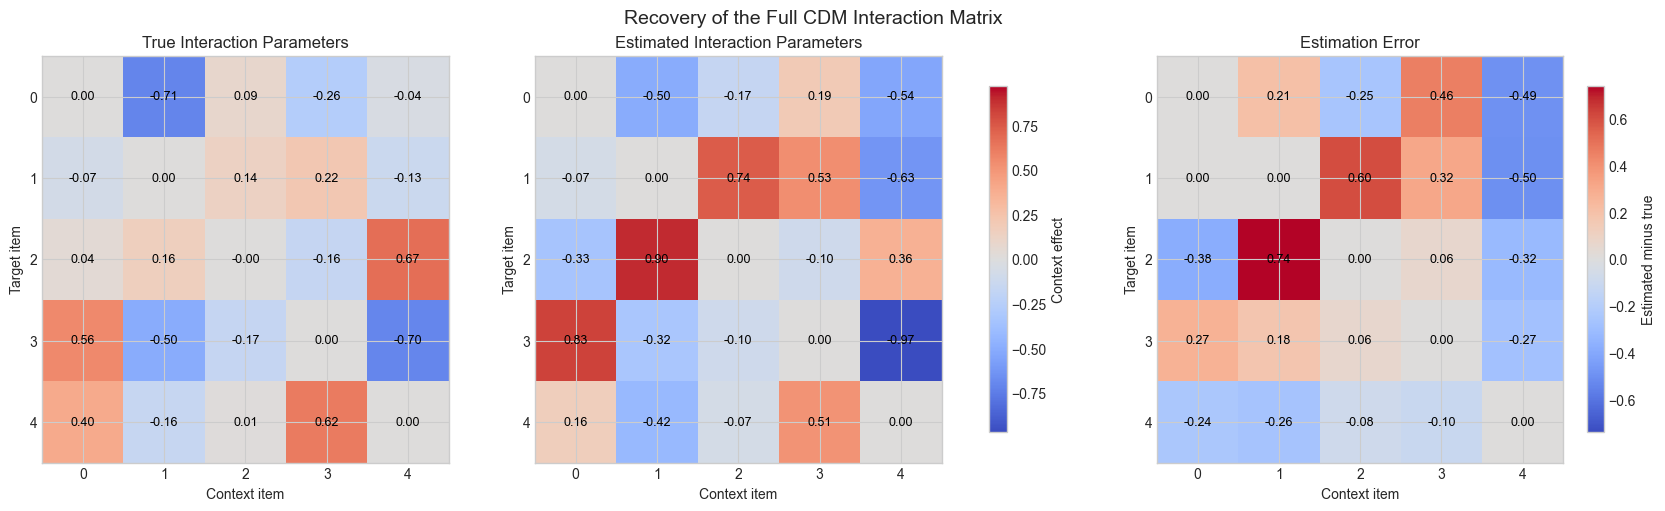

In [19]:
# Compare the true, estimated and error interaction matrices.

true_values = (
    true_interactions.detach().cpu().numpy()
)

estimated_values = (
    estimated_interactions.detach().cpu().numpy()
)

difference_values = (
    estimated_values - true_values
)

parameter_limit = max(
    abs(true_values).max(),
    abs(estimated_values).max(),
)

error_limit = abs(difference_values).max()

figure, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
    constrained_layout=True,
)

true_image = axes[0].imshow(
    true_values,
    cmap="coolwarm",
    vmin=-parameter_limit,
    vmax=parameter_limit,
)

axes[1].imshow(
    estimated_values,
    cmap="coolwarm",
    vmin=-parameter_limit,
    vmax=parameter_limit,
)

error_image = axes[2].imshow(
    difference_values,
    cmap="coolwarm",
    vmin=-error_limit,
    vmax=error_limit,
)

titles = [
    "True Interaction Parameters",
    "Estimated Interaction Parameters",
    "Estimation Error",
]

matrices = [
    true_values,
    estimated_values,
    difference_values,
]

for axis, title, matrix in zip(
    axes,
    titles,
    matrices,
):
    axis.set_title(title)
    axis.set_xlabel("Context item")
    axis.set_ylabel("Target item")

    axis.set_xticks(range(NUMBER_OF_ITEMS))
    axis.set_yticks(range(NUMBER_OF_ITEMS))

    for target_item in range(NUMBER_OF_ITEMS):
        for context_item in range(NUMBER_OF_ITEMS):
            axis.text(
                context_item,
                target_item,
                f"{matrix[target_item, context_item]:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black",
            )

figure.colorbar(
    true_image,
    ax=axes[:2],
    label="Context effect",
    shrink=0.85,
)

figure.colorbar(
    error_image,
    ax=axes[2],
    label="Estimated minus true",
    shrink=0.85,
)

figure.suptitle(
    "Recovery of the Full CDM Interaction Matrix",
    fontsize=14,
)

plt.show()
figure.savefig(
    CDM_CDM_FIGURE_DIRECTORY
    / "01_full_cdm_parameter_recovery.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()

In [20]:
# Check how evenly the training observations cover different choice sets.

training_choice_set_labels = []

for observation_index in range(
    len(training_data.choice_sets)
):
    available_items = training_data.choice_sets[
        observation_index
    ][
        training_data.choice_mask[
            observation_index
        ]
    ].cpu().tolist()

    training_choice_set_labels.append(
        tuple(sorted(available_items))
    )

choice_set_counts = pd.Series(
    training_choice_set_labels
).value_counts()

number_of_possible_sets = sum(
    comb(NUMBER_OF_ITEMS, choice_set_size)
    for choice_set_size in CHOICE_SET_SIZES
)

coverage_summary = pd.DataFrame({
    "Quantity": [
        "Possible choice sets",
        "Observed choice sets in training",
        "Least observations for one set",
        "Most observations for one set",
        "Mean observations per set",
    ],
    "Value": [
        number_of_possible_sets,
        len(choice_set_counts),
        int(choice_set_counts.min()),
        int(choice_set_counts.max()),
        choice_set_counts.mean(),
    ],
})

coverage_summary.style.format({
    "Value": "{:.2f}",
})

,Quantity,Value
0,Possible choice sets,20.00
1,Observed choice sets in training,20.00
2,Least observations for one set,32.00
3,Most observations for one set,55.00
4,Mean observations per set,40.00


All this 20 possible choice sets are represented in the training data, with reasonably makes the
balanced observation counts. So, maybe the weak parameter recovery is not
caused by missing choice sets. Instead it might be that approximately 40 observations per set
appear insufficient for accurately estimating the full interaction matrix.

## Experiment 2: Recovery as the Number of Observations Increases


In [21]:
# Define settings for the observation-scaling experiment.

OBSERVATION_COUNTS = [
    1_000,
    5_000,
    10_000,
    50_000,
]

NUMBER_OF_RUNS = 10

SCALING_SEEDS = [
    SEED + run
    for run in range(NUMBER_OF_RUNS)
]

observation_scaling_settings = pd.DataFrame({
    "Setting": [
        "Fixed number of items",
        "Observation counts",
        "Independent runs per setting",
        "Training fraction",
        "True interaction matrix",
    ],
    "Value": [
        NUMBER_OF_ITEMS,
        str(OBSERVATION_COUNTS),
        NUMBER_OF_RUNS,
        TRAIN_FRACTION,
        "Fixed across all runs",
    ],
})

observation_scaling_settings

,Setting,Value
0,Fixed number of items,5
1,Observation counts,"[1000, 5000, 10000, 50000]"
2,Independent runs per setting,10
3,Training fraction,0.8
4,True interaction matrix,Fixed across all runs


In [22]:
# Verify the experiment pipeline using one small trial.

smoke_test_results = pd.DataFrame(
    run_cdm_observation_scaling_experiment(
        true_interactions=true_interactions,
        observation_counts=[1_000],
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=[SCALING_SEEDS[0]],
        train_fraction=TRAIN_FRACTION,
        learning_rate=LEARNING_RATE,
        gradient_tolerance=GRADIENT_TOLERANCE,
        nll_tolerance=NLL_TOLERANCE,
        patience=CONVERGENCE_PATIENCE,
        maximum_epochs=MAXIMUM_EPOCHS,
    )
)

smoke_test_results

Running 1/1: observations=1,000, run=1
All observation-scaling trials completed.


,Number of observations,Run,Random seed,Training observations,Test observations,Parameter RMSE,Parameter correlation,Uniform test NLL,True test NLL,Estimated test NLL,Epochs,Runtime (seconds),Converged,Stopping reason
0,1000,1,20260831,800,200,0.3459,0.7286,0.904,0.802,0.819,169,0.1079,True,gradient tolerance reached


### Repeated Observation-Scaling Runs, 40 runs


In [23]:
# Run repeated recovery experiments for every observation count.

observation_scaling_results = pd.DataFrame(
    run_cdm_observation_scaling_experiment(
        true_interactions=true_interactions,
        observation_counts=OBSERVATION_COUNTS,
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=SCALING_SEEDS,
        train_fraction=TRAIN_FRACTION,
        learning_rate=LEARNING_RATE,
        gradient_tolerance=GRADIENT_TOLERANCE,
        nll_tolerance=NLL_TOLERANCE,
        patience=CONVERGENCE_PATIENCE,
        maximum_epochs=MAXIMUM_EPOCHS,
    )
)

observation_scaling_results.head()

Running 1/40: observations=1,000, run=1
Running 2/40: observations=1,000, run=2
Running 3/40: observations=1,000, run=3
Running 4/40: observations=1,000, run=4
Running 5/40: observations=1,000, run=5
Running 6/40: observations=1,000, run=6
Running 7/40: observations=1,000, run=7
Running 8/40: observations=1,000, run=8
Running 9/40: observations=1,000, run=9
Running 10/40: observations=1,000, run=10
Running 11/40: observations=5,000, run=1
Running 12/40: observations=5,000, run=2
Running 13/40: observations=5,000, run=3
Running 14/40: observations=5,000, run=4
Running 15/40: observations=5,000, run=5
Running 16/40: observations=5,000, run=6
Running 17/40: observations=5,000, run=7
Running 18/40: observations=5,000, run=8
Running 19/40: observations=5,000, run=9
Running 20/40: observations=5,000, run=10
Running 21/40: observations=10,000, run=1
Running 22/40: observations=10,000, run=2
Running 23/40: observations=10,000, run=3
Running 24/40: observations=10,000, run=4
Running 25/40: obse

,Number of observations,Run,Random seed,Training observations,Test observations,Parameter RMSE,Parameter correlation,Uniform test NLL,True test NLL,Estimated test NLL,Epochs,Runtime (seconds),Converged,Stopping reason
0,1000,1,20260831,800,200,0.3459,0.7286,0.9040,0.8020,0.8190,169,0.1039,True,gradient tolerance reached
1,1000,2,20260832,800,200,0.3420,0.6599,0.9141,0.8743,0.8737,183,0.1095,True,gradient tolerance reached
2,1000,3,20260833,800,200,0.1848,0.9124,0.8979,0.8385,0.8540,166,0.1014,True,gradient tolerance reached
3,1000,4,20260834,800,200,0.4922,0.4731,0.9080,0.8522,0.8534,179,0.1125,True,gradient tolerance reached
4,1000,5,20260835,800,200,0.3187,0.7962,0.8837,0.8324,0.8508,196,0.1167,True,gradient tolerance reached


In [24]:
# Summarise recovery, prediction and runtime across repeated runs.

observation_scaling_results[
    "Excess test NLL"
] = (
    observation_scaling_results[
        "Estimated test NLL"
    ]
    - observation_scaling_results[
        "True test NLL"
    ]
)

observation_scaling_summary = (
    observation_scaling_results
    .groupby(
        "Number of observations",
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_parameter_RMSE=(
            "Parameter RMSE",
            "mean",
        ),
        RMSE_std=(
            "Parameter RMSE",
            "std",
        ),
        Mean_parameter_correlation=(
            "Parameter correlation",
            "mean",
        ),
        Mean_excess_test_NLL=(
            "Excess test NLL",
            "mean",
        ),
        Mean_epochs=(
            "Epochs",
            "mean",
        ),
        Mean_runtime=(
            "Runtime (seconds)",
            "mean",
        ),
        Convergence_rate=(
            "Converged",
            "mean",
        ),
    )
)

observation_scaling_summary[
    "Convergence_rate"
] *= 100

observation_scaling_summary.style.format({
    "Number of observations": "{:,}",
    "Runs": "{:,}",
    "Mean_parameter_RMSE": "{:.4f}",
    "RMSE_std": "{:.4f}",
    "Mean_parameter_correlation": "{:.4f}",
    "Mean_excess_test_NLL": "{:.4f}",
    "Mean_epochs": "{:.2f}",
    "Mean_runtime": "{:.4f}",
    "Convergence_rate": "{:.1f}%",
})

,Number of observations,Runs,Mean_parameter_RMSE,RMSE_std,Mean_parameter_correlation,Mean_excess_test_NLL,Mean_epochs,Mean_runtime,Convergence_rate
0,"1,000",10,0.3243,0.0888,0.7519,0.0100,176.10,0.1115,100.0%
1,"5,000",10,0.1216,0.0321,0.9493,0.0023,164.10,0.2348,100.0%
2,"10,000",10,0.0984,0.0247,0.9673,0.0016,163.30,0.3995,100.0%
3,"50,000",10,0.0482,0.0115,0.9920,0.0003,161.50,1.3972,100.0%


### Visualising Observation-Scaling Results


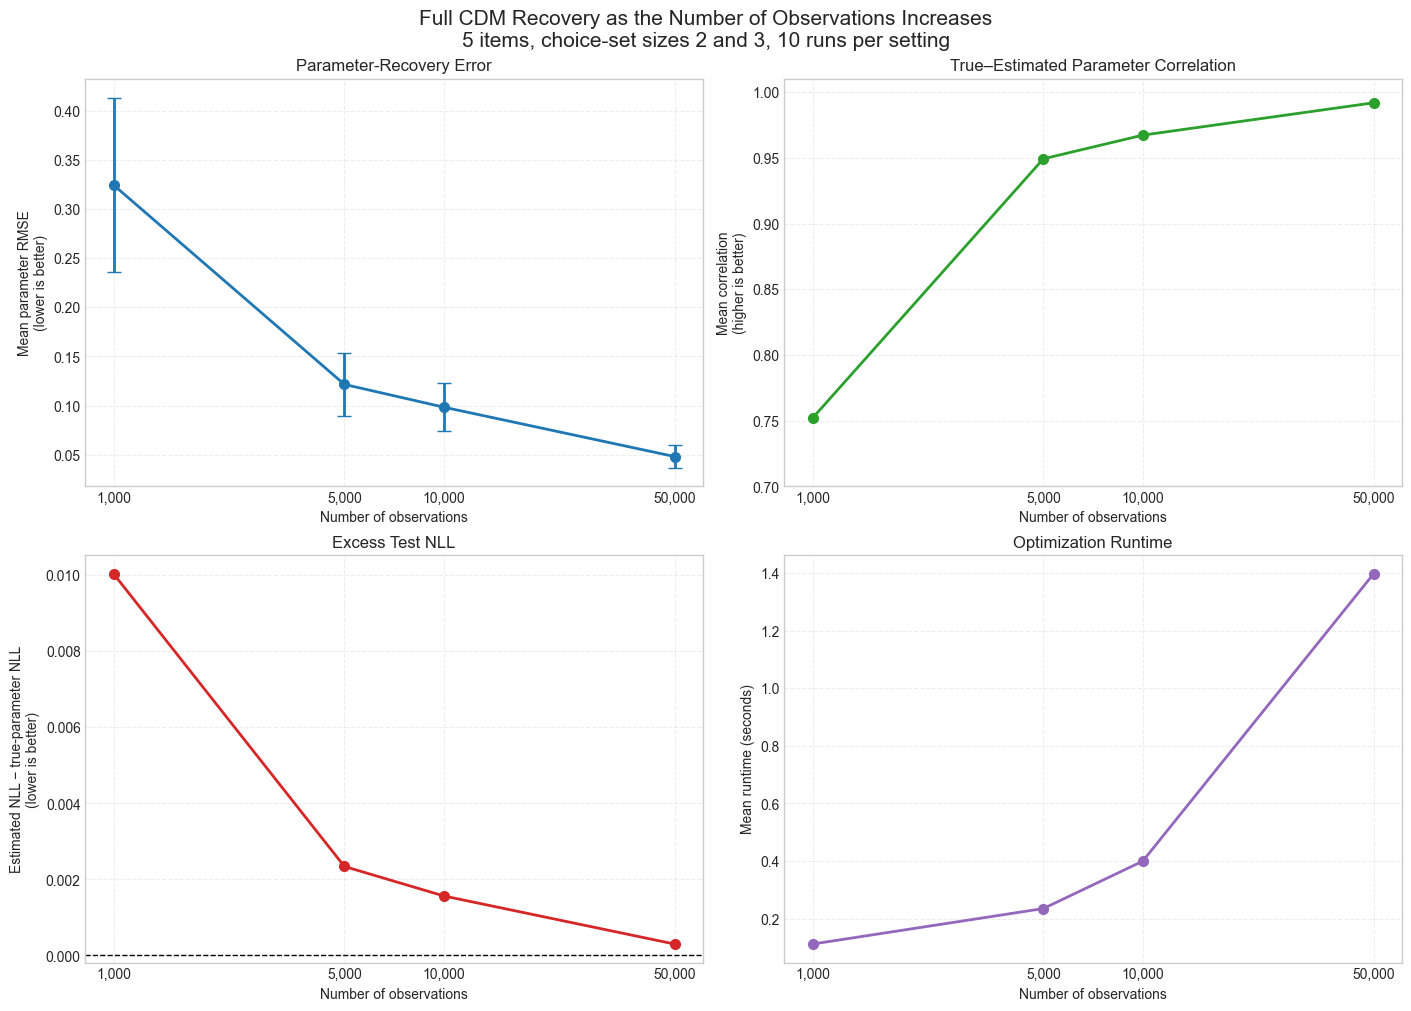

In [ ]:
plot_data = observation_scaling_summary.copy()

observation_counts = plot_data["Number of observations"].to_numpy()

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    constrained_layout=True,
)

# 1. Parameter RMSE
axes[0, 0].errorbar(
    observation_counts,
    plot_data["Mean_parameter_RMSE"],
    yerr=plot_data["RMSE_std"],
    marker="o",
    linewidth=2,
    markersize=7,
    capsize=5,
    color="#1f77b4",
)

axes[0, 0].set_title("Parameter-Recovery Error")
axes[0, 0].set_ylabel("Mean parameter RMSE\n(lower is better)")


# 2. Parameter correlation
axes[0, 1].plot(
    observation_counts,
    plot_data["Mean_parameter_correlation"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#2ca02c",
)

axes[0, 1].set_title("True–Estimated Parameter Correlation")
axes[0, 1].set_ylabel("Mean correlation\n(higher is better)")
axes[0, 1].set_ylim(0.70, 1.01)


# 3. Excess test NLL
axes[1, 0].plot(
    observation_counts,
    plot_data["Mean_excess_test_NLL"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#d62728",
)

axes[1, 0].axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1,
)

axes[1, 0].set_title("Excess Test NLL")
axes[1, 0].set_ylabel(
    "Estimated NLL − true-parameter NLL\n(lower is better)"
)


# 4. Runtime
axes[1, 1].plot(
    observation_counts,
    plot_data["Mean_runtime"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#9467bd",
)

axes[1, 1].set_title("Optimization Runtime")
axes[1, 1].set_ylabel("Mean runtime (seconds)")


# Common formatting
for axis in axes.flat:
    axis.set_xscale("log")
    axis.set_xticks(observation_counts)
    axis.set_xticklabels(
        [f"{int(count):,}" for count in observation_counts]
    )
    axis.set_xlabel("Number of observations")
    axis.grid(True, linestyle="--", alpha=0.35)

figure.suptitle(
    "Full CDM Recovery as the Number of Observations Increases\n"
    "5 items, choice-set sizes 2 and 3, 10 runs per setting",
    fontsize=15,
)
figure.savefig(
    CDM_CDM_FIGURE_DIRECTORY
    / "02_recovery_vs_observations.pdf",
    bbox_inches="tight",
    dpi=300,
)



plt.show()

## Experiment 3: Scaling with the Number of Items


In [26]:
ITEM_COUNTS = [5, 10, 20, 40, 80]
FIXED_NUMBER_OF_OBSERVATIONS = 50_000
ITEM_SCALING_RUNS = 5

ITEM_SCALING_SEEDS = [
    SEED + 1_000 + run
    for run in range(ITEM_SCALING_RUNS)
]

item_scaling_settings = pd.DataFrame(
    {
        "Setting": [
            "Number of items",
            "Fixed number of observations",
            "Independent runs per setting",
            "Choice-set sizes",
            "PyTorch device",
            "PyTorch dtype",
        ],
        "Value": [
            ITEM_COUNTS,
            FIXED_NUMBER_OF_OBSERVATIONS,
            ITEM_SCALING_RUNS,
            CHOICE_SET_SIZES,
            DEVICE,
            DTYPE,
        ],
    }
)

item_scaling_settings

,Setting,Value
0,Number of items,"[5, 10, 20, 40, 80]"
1,Fixed number of observations,50000
2,Independent runs per setting,5
3,Choice-set sizes,"(2, 3)"
4,PyTorch device,cpu
5,PyTorch dtype,torch.float64


In [27]:
import inspect

print(
    inspect.signature(
        run_cdm_observation_scaling_experiment
    )
)

(true_interactions: 'torch.Tensor', observation_counts: 'Sequence[int]', choice_set_sizes: 'Sequence[int]', random_seeds: 'Sequence[int]', *, train_fraction: 'float' = 0.8, learning_rate: 'float' = 0.05, gradient_tolerance: 'float' = 1e-05, nll_tolerance: 'float' = 1e-09, patience: 'int' = 50, maximum_epochs: 'int' = 5000) -> 'list[dict]'


### Item-Scaling Smoke Test


In [28]:
item_scaling_smoke_test = pd.DataFrame(
    run_cdm_item_scaling_experiment(
        item_counts=[5],
        number_of_observations=1_000,
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=[ITEM_SCALING_SEEDS[0]],
        parameter_scale=PARAMETER_SCALE,
        parameter_seed=SEED,
        device=DEVICE,
        dtype=DTYPE,
    )
)

item_scaling_smoke_test

Running 1/1: observations=1,000, run=1
All observation-scaling trials completed.


,Number of observations,Run,Random seed,Training observations,Test observations,Parameter RMSE,Parameter correlation,Uniform test NLL,True test NLL,Estimated test NLL,Epochs,Runtime (seconds),Converged,Stopping reason,Number of items,Number of free parameters,Parameter seed
0,1000,1,20261831,800,200,0.3453,0.7318,0.8675,0.838,0.8515,150,0.0887,True,gradient tolerance reached,5,19,20260836


### Repeated Item-Scaling Runs


In [ ]:
item_scaling_results = pd.DataFrame(
    run_cdm_item_scaling_experiment(
        item_counts=ITEM_COUNTS,
        number_of_observations=FIXED_NUMBER_OF_OBSERVATIONS,
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=ITEM_SCALING_SEEDS,
        parameter_scale=PARAMETER_SCALE,
        parameter_seed=SEED,
        device=DEVICE,
        dtype=DTYPE,
    )
)

display_columns = [
    "Number of items",
    "Number of free parameters",
    "Number of observations",
    "Run",
    "Parameter RMSE",
    "Parameter correlation",
    "True test NLL",
    "Estimated test NLL",
    "Epochs",
    "Runtime (seconds)",
    "Converged",
]

item_scaling_results[display_columns]

Running 1/5: observations=50,000, run=1
Running 2/5: observations=50,000, run=2
Running 3/5: observations=50,000, run=3
Running 4/5: observations=50,000, run=4
Running 5/5: observations=50,000, run=5
All observation-scaling trials completed.
Running 1/5: observations=50,000, run=1
Running 2/5: observations=50,000, run=2
Running 3/5: observations=50,000, run=3
Running 4/5: observations=50,000, run=4
Running 5/5: observations=50,000, run=5
All observation-scaling trials completed.
Running 1/5: observations=50,000, run=1
Running 2/5: observations=50,000, run=2
Running 3/5: observations=50,000, run=3
Running 4/5: observations=50,000, run=4
Running 5/5: observations=50,000, run=5
All observation-scaling trials completed.
Running 1/5: observations=50,000, run=1
Running 2/5: observations=50,000, run=2
Running 3/5: observations=50,000, run=3
Running 4/5: observations=50,000, run=4
Running 5/5: observations=50,000, run=5
All observation-scaling trials completed.
Running 1/5: observations=50,000

summary

In [ ]:
item_scaling_results["Excess test NLL"] = (
    item_scaling_results["Estimated test NLL"]
    - item_scaling_results["True test NLL"]
)

item_scaling_summary = (
    item_scaling_results.groupby(
        [
            "Number of items",
            "Number of free parameters",
            "Number of observations",
        ],
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_parameter_RMSE=("Parameter RMSE", "mean"),
        RMSE_std=("Parameter RMSE", "std"),
        Mean_parameter_correlation=(
            "Parameter correlation",
            "mean",
        ),
        Mean_excess_test_NLL=("Excess test NLL", "mean"),
        Mean_epochs=("Epochs", "mean"),
        Mean_runtime=("Runtime (seconds)", "mean"),
        Runtime_std=("Runtime (seconds)", "std"),
        Convergence_rate=("Converged", "mean"),
    )
)

item_scaling_summary["Observations_per_parameter"] = (
    item_scaling_summary["Number of observations"]
    / item_scaling_summary["Number of free parameters"]
)

item_scaling_summary["Convergence_rate"] *= 100

item_scaling_summary.style.format(
    {
        "Number of free parameters": "{:,}",
        "Number of observations": "{:,}",
        "Runs": "{:,}",
        "Mean_parameter_RMSE": "{:.4f}",
        "RMSE_std": "{:.4f}",
        "Mean_parameter_correlation": "{:.4f}",
        "Mean_excess_test_NLL": "{:.4f}",
        "Mean_epochs": "{:.2f}",
        "Mean_runtime": "{:.4f}",
        "Runtime_std": "{:.4f}",
        "Convergence_rate": "{:.1f}%",
        "Observations_per_parameter": "{:.2f}",
    }
)

,Number of items,Number of free parameters,Number of observations,Runs,Mean_parameter_RMSE,RMSE_std,Mean_parameter_correlation,Mean_excess_test_NLL,Mean_epochs,Mean_runtime,Runtime_std,Convergence_rate,Observations_per_parameter
0,5,19,"50,000",5,0.0520,0.0132,0.9843,0.0000,147.40,1.2976,0.1710,100.0%,2631.58
1,10,89,"50,000",5,0.0945,0.0114,0.9692,0.0009,145.40,1.1922,0.0202,100.0%,561.80
2,20,379,"50,000",5,0.1683,0.0054,0.9192,0.0052,146.00,1.1872,0.0662,100.0%,131.93
3,40,"1,559","50,000",5,0.3303,0.0118,0.7860,0.0190,153.80,1.2725,0.0705,100.0%,32.07
4,80,"6,319","50,000",5,0.8017,0.0210,0.5099,0.1152,325.80,2.8023,0.4342,100.0%,7.91


In [ ]:
item_scaling_summary[
    "Training_observations_per_parameter"
] = (
    FIXED_NUMBER_OF_OBSERVATIONS
    * TRAIN_FRACTION
    / item_scaling_summary["Number of free parameters"]
)

item_scaling_summary = item_scaling_summary.drop(
    columns=["Observations_per_parameter"]
)

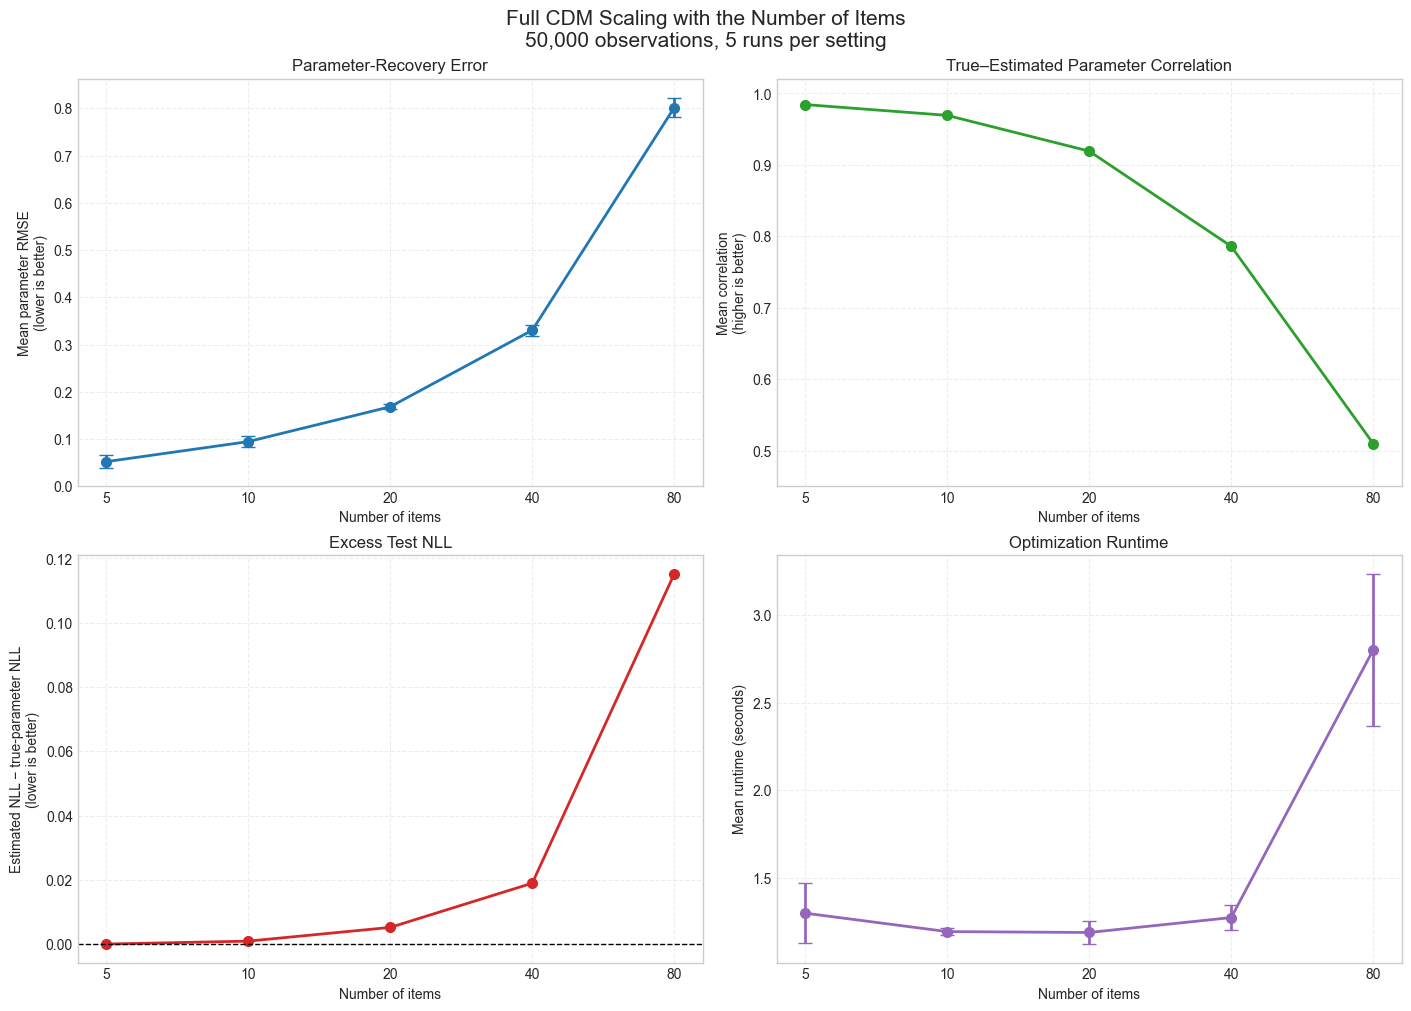

In [ ]:
plot_data = item_scaling_summary.copy()
item_counts = plot_data["Number of items"].to_numpy()

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    constrained_layout=True,
)

# Parameter-recovery error
axes[0, 0].errorbar(
    item_counts,
    plot_data["Mean_parameter_RMSE"],
    yerr=plot_data["RMSE_std"],
    marker="o",
    linewidth=2,
    markersize=7,
    capsize=5,
    color="#1f77b4",
)

axes[0, 0].set_title("Parameter-Recovery Error")
axes[0, 0].set_ylabel("Mean parameter RMSE\n(lower is better)")


# Parameter correlation
axes[0, 1].plot(
    item_counts,
    plot_data["Mean_parameter_correlation"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#2ca02c",
)

axes[0, 1].set_title("True–Estimated Parameter Correlation")
axes[0, 1].set_ylabel("Mean correlation\n(higher is better)")
axes[0, 1].set_ylim(0.45, 1.02)


# Excess test NLL
axes[1, 0].plot(
    item_counts,
    plot_data["Mean_excess_test_NLL"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#d62728",
)

axes[1, 0].axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1,
)

axes[1, 0].set_title("Excess Test NLL")
axes[1, 0].set_ylabel(
    "Estimated NLL − true-parameter NLL\n(lower is better)"
)


# Optimization runtime
axes[1, 1].errorbar(
    item_counts,
    plot_data["Mean_runtime"],
    yerr=plot_data["Runtime_std"],
    marker="o",
    linewidth=2,
    markersize=7,
    capsize=5,
    color="#9467bd",
)

axes[1, 1].set_title("Optimization Runtime")
axes[1, 1].set_ylabel("Mean runtime (seconds)")


for axis in axes.flat:
    axis.set_xscale("log", base=2)
    axis.set_xticks(item_counts)
    axis.set_xticklabels(item_counts)
    axis.set_xlabel("Number of items")
    axis.grid(True, linestyle="--", alpha=0.35)

figure.suptitle(
    "Full CDM Scaling with the Number of Items\n"
    "50,000 observations, 5 runs per setting",
    fontsize=15,
)

plt.show()

## Observation:
 With 5 item, the model (5 item= 19 parameters) is getting good parameter recovery, but for 80 items, which has 6319 free params has now only about 6.3 observation per param.
 Also we can see that the RMSE is increasing and co-relation decreasing.
So we can conclude by saying that the full CDM becomes statistically difficult to
estimate as the number of items increases.

### Now, let's search for computational limit.

nahi karna, maan liya hota hai intractable